# Cluster Effects Preprocessing

**Fine-tuned EmbeddingGemma 2 version** of `main/code/02_cluster_centroid_products.ipynb`: the DoubleMLDeep product embeddings are replaced by [EmbeddingGemma 2](https://huggingface.co/google/embeddinggemma-2) embeddings fine-tuned with LoRA and the loss of the DoubleMLDeep model on the training sample (`finetune_gemma.py`, `00_finetune_gemma_colab.ipynb`; text + image, Matryoshka 256 dimensions; the text-only embeddings are the fine-tuned EmbeddingGemma 2 text-only embeddings, also with 256 dimensions). Datasets are read from `Gemma-tuned/data`, raw data from `main/data`, outputs are written to `Gemma-tuned/outputs`.

In [1]:
import os
import datasets
import pandas as pd
import numpy as np
import lightning.pytorch as pl

import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib import cm

from pathlib import Path
from PIL import Image, ImageDraw, ImageFont
import textwrap
from IPython.display import display  # Import display function

import doubleml as dml
from doubleml.utils import DMLDummyRegressor

from sklearn.cluster import KMeans
from sklearn.preprocessing import PolynomialFeatures, StandardScaler, normalize
from sklearn.decomposition import PCA
from sklearn.metrics import r2_score, pairwise_distances
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from lightgbm import LGBMRegressor
from utils.utils_gemma import load_embeddings
from utils.utils_data2 import (
    load_pred_and_emb,
    center_and_norm,
    get_pca,
    get_cluster,
    get_similarities,
    add_lags_and_scale_data,
)

confidence_level = 0.9
ci_level_name = f"{round((confidence_level) * 100, 1)}%"
ci_names = [
    f"{round((1 - confidence_level) * 100 / 2, 1)}%",
    f"{round((1 + confidence_level) * 100 / 2, 1)}%",
]
print(ci_level_name)
print(ci_names)

/tmp/claude-0/-home-user-demand-analysis-repro/8871aba3-e06d-5440-87b8-bf4072e29cf1/scratchpad/venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


90.0%
['5.0%', '95.0%']


## Set Output Directory

In [2]:
output_dir = "../outputs/02_cluster_centroid_products"
Path(output_dir).mkdir(parents=True, exist_ok=True)


## Data Loading and Preprocessing

In [3]:
txt_only = False
include_embeddings = True
dataframe_name = f"dataset_txt_only_{txt_only}_embeddings_{include_embeddings}"
df_full_train = pd.read_csv(f"../data/{dataframe_name}_train.zip")
df_full_val = pd.read_csv(f"../data/{dataframe_name}_val.zip")

columns_to_drop = []

df_full_train = df_full_train.drop(columns=columns_to_drop)
df_full_val = df_full_val.drop(columns=columns_to_drop)

df_full_train = df_full_train.dropna()
df_full_val = df_full_val.dropna()

dummy_subcat_names = [
    category for category in df_full_val["subcat_aggregated"].unique()
]
all_time_steps = sorted([str(date) for date in df_full_val["date"].unique()])

print(f"Dummy subcat names: {dummy_subcat_names}")
print(f"All time steps: {all_time_steps}")
df_full_val.columns

data_files = {
    "train": [f"train-0000{i}-of-00004-part00{j}.parquet" for i in range(4) for j in range(4)],
}

ds_img = datasets.load_dataset(
    "parquet",
    data_dir="../../main/data/amzn_toys_monthly_avg_long_ffill_28_7_images",
    data_files=data_files,
)

df_img = ds_img["train"].to_pandas()

Dummy subcat names: ['Residual', 'Cars & Race Cars', 'Trains & Trams', 'Train Sets', 'Trucks', 'Tractors', 'Race Tracks', 'Airplanes', 'Motor Vehicles', 'Vehicle Playsets', 'Skateboards']
All time steps: ['2023-03-27', '2023-04-24', '2023-05-22', '2023-06-19', '2023-07-17', '2023-08-14', '2023-09-11', '2023-10-09', '2023-11-06', '2023-12-04', '2024-01-01', '2024-01-29']


In [4]:
# text-only embeddings: fine-tuned EmbeddingGemma 2 (text only, Matryoshka 256 dimensions)
# instead of the time-independent DoubleMLDeep text-only model
emb_txt = load_embeddings("../data/finetuned/txt/embeddinggemma2_tuned_txt.parquet", emb_dim=256)
print(f"Text-only embeddings: {emb_txt.shape}")

Text-only embeddings: (7549, 256)


In [5]:
# product-level embeddings broadcast to the (ASIN, date) panel
train_emb_txt = emb_txt.loc[df_full_train["ASIN"]].set_axis(
    pd.MultiIndex.from_frame(df_full_train[["ASIN", "date"]])
)
val_emb_txt = emb_txt.loc[df_full_val["ASIN"]].set_axis(
    pd.MultiIndex.from_frame(df_full_val[["ASIN", "date"]])
)

train_emb_txt.columns = [f"{x}_txt" for x in train_emb_txt.columns]
val_emb_txt.columns = [f"{x}_txt" for x in val_emb_txt.columns]

df_full_train = df_full_train.set_index(["ASIN", "date"]).join(train_emb_txt)
df_full_val = df_full_val.set_index(["ASIN", "date"]).join(val_emb_txt)

In [6]:
columns = [
    "ASIN",
    "Q_t",
    "P_bb_t",
    "text",
    "date",
    "window",
    "REVIEW_COUNT",
    "RATING",
    "New Offer Count: Current",
    "Count of retrieved live offers: New, FBA",
    "Count of retrieved live offers: New, FBM",
    "Lightning Deals: Upcoming Deal",
    "Buy Box: Is FBA",
    "subcat_aggregated",
]

# Clustering

In [7]:
emb_columns = ["ASIN", "date"] + [f"emb_{i}" for i in range(256)]
emb_columns_txt = ["ASIN", "date"] + [f"emb_{i}_txt" for i in range(256)]

In [8]:
full_embeddings_txtimg = center_and_norm(
    df_full_train.reset_index()[emb_columns], df_full_val.reset_index()[emb_columns]
)

full_embeddings_txtimg.shape

(68766, 256)

In [9]:
full_embeddings_txt = center_and_norm(
    df_full_train.reset_index()[emb_columns_txt],
    df_full_val.reset_index()[emb_columns_txt],
)

full_embeddings_txt.shape

(68766, 256)

In [10]:
kmeans_txt_labels, cluster_centroids_txt = get_cluster(
    full_embeddings_txt, n_clusters=5
)
kmeans_txtimg_labels, cluster_centroids_txtimg = get_cluster(
    full_embeddings_txtimg, n_clusters=5
)

## PCA Visualization

In [11]:
pca_img = PCA(n_components=2, random_state=42)
pca_img_results = pca_img.fit_transform(full_embeddings_txtimg)

pca_txt = PCA(n_components=2, random_state=42)
pca_txt_results = pca_txt.fit_transform(full_embeddings_txt)

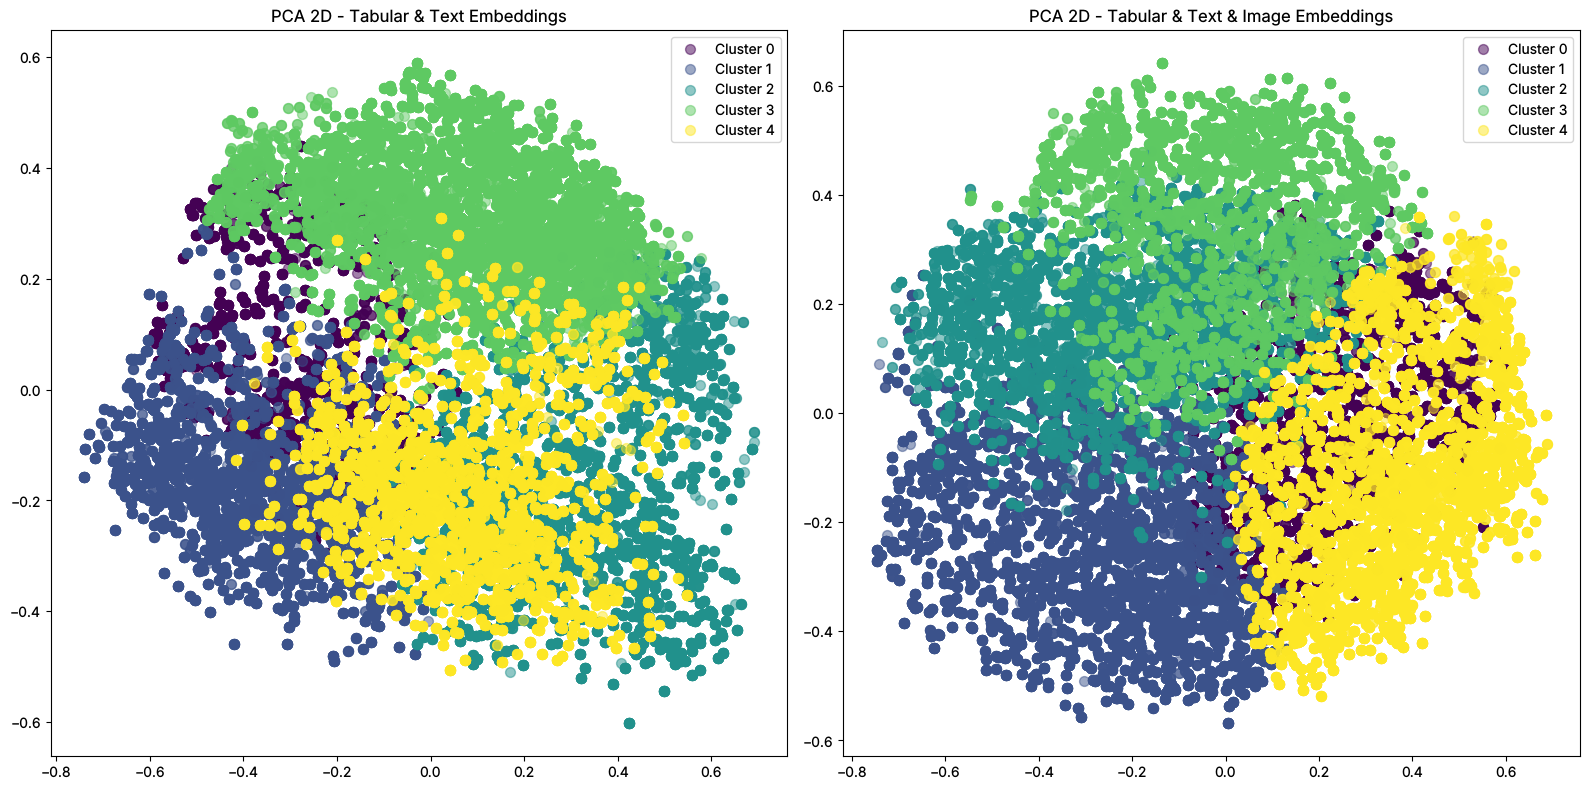

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# Plot for text embeddings
unique_cluster_ids = np.unique(kmeans_txt_labels)
colors = cm.viridis(np.linspace(0, 1, len(unique_cluster_ids)))

for i, cluster_id in enumerate(unique_cluster_ids):
    axes[0].scatter(
        pca_txt_results[kmeans_txt_labels == cluster_id, 0],
        pca_txt_results[kmeans_txt_labels == cluster_id, 1],
        color=colors[i],
        label=f"Cluster {cluster_id}",
        s=50,
        alpha=0.5,
    )
axes[0].set_title("PCA 2D - Tabular & Text Embeddings")
axes[0].legend()

# Plot for image embeddings
unique_cluster_ids = np.unique(kmeans_txtimg_labels)

for i, cluster_id in enumerate(unique_cluster_ids):
    axes[1].scatter(
        pca_img_results[kmeans_txtimg_labels == cluster_id, 0],
        pca_img_results[kmeans_txtimg_labels == cluster_id, 1],
        color=colors[i],
        label=f"Cluster {cluster_id}",
        s=50,
        alpha=0.5,
    )
axes[1].set_title("PCA 2D - Tabular & Text & Image Embeddings")
axes[1].legend()

plt.tight_layout()
plt.savefig(os.path.join(output_dir, "pca_2d_clusters.png"))
plt.show()

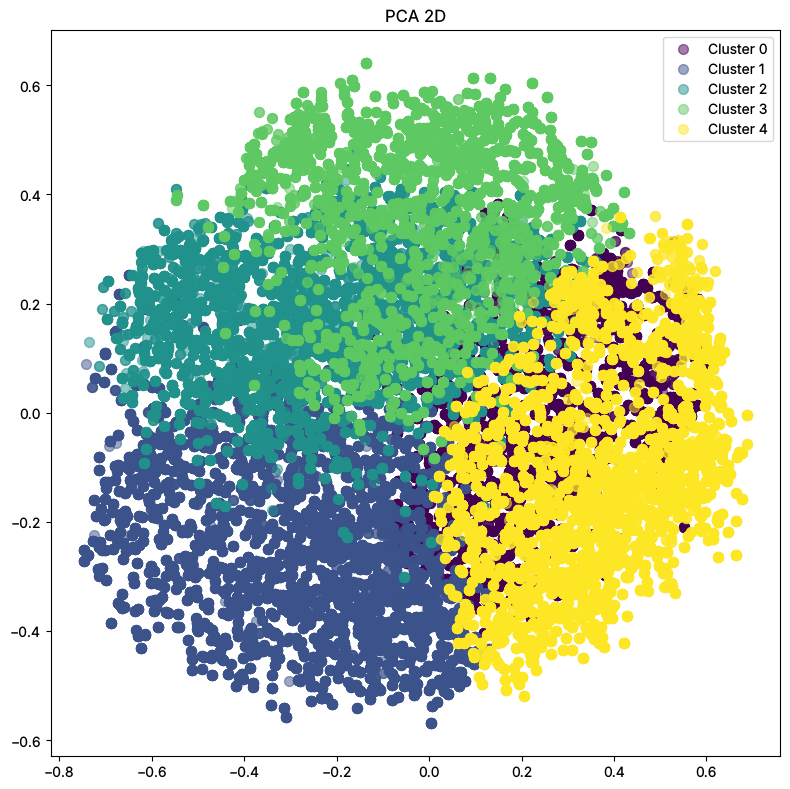

In [13]:
fig = plt.figure(figsize=(8, 8))
unique_cluster_ids = np.unique(kmeans_txtimg_labels)
colors = cm.viridis(np.linspace(0, 1, len(unique_cluster_ids)))

for i, cluster_id in enumerate(unique_cluster_ids):
    plt.scatter(
        pca_img_results[kmeans_txtimg_labels == cluster_id, 0],
        pca_img_results[kmeans_txtimg_labels == cluster_id, 1],
        color=colors[i],
        label=f"Cluster {cluster_id}",
        s=50,
        alpha=0.5,
    )
plt.title("PCA 2D")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(output_dir, "pca_img_clusters.png"))
plt.show()

## 3D PCA Visualization

In [14]:
pca_img_3d = PCA(n_components=3, random_state=42)
pca_img_3d_results = pca_img_3d.fit_transform(full_embeddings_txtimg)

pca_txt_3d = PCA(n_components=3, random_state=42)
pca_txt_3d_results = pca_txt_3d.fit_transform(full_embeddings_txt)

In [15]:
import plotly.graph_objs as go
from plotly.subplots import make_subplots
import matplotlib.colors as mcolors  # To convert colors to hex

colors = [
    mcolors.rgb2hex(cm.viridis(i)) for i in np.linspace(0, 1, len(unique_cluster_ids))
]

fig = make_subplots(rows=1, cols=1, specs=[[{"type": "scatter3d"}]])


# Convert index to row and column in a 2x2 grid
row, col = divmod(0, 1)

# Create traces for each cluster
for i, cluster_id in enumerate(unique_cluster_ids):
    mask = kmeans_txtimg_labels == cluster_id
    fig.add_trace(
        go.Scatter3d(
            x=pca_img_3d_results[mask, 0],  # PC1
            y=pca_img_3d_results[mask, 1],  # PC2
            z=pca_img_3d_results[mask, 2],  # PC3
            mode="markers",
            marker=dict(size=5, color=colors[i], opacity=0.075),
            name=f"Cluster {cluster_id}",
        ),
        row=row + 1,
        col=col + 1,
    )

# Step 5: Set titles and layout
fig.update_layout(
    height=800,
    width=800,
    template="none",
    margin=dict(t=5, r=20, b=10, l=20),
    scene=dict(
        xaxis=dict(range=[-1, 1]),
        yaxis=dict(range=[-1, 1]),
        zaxis=dict(range=[-1, 1]),
        camera_eye=dict(x=1, y=2, z=1),
    ),
)

fig.update_layout(
    legend=dict(
        x=0.5,  # Center the legend horizontally
        y=-0.01,  # Place the legend below the plot
        xanchor="center",  # Align legend horizontally by its center
        yanchor="top",  # Align legend vertically by its top
        orientation="h",  # Arrange legend items horizontally
        bgcolor="rgba(255, 255, 255, 0.7)",  # Optional: Add a semi-transparent background
        bordercolor="black",  # Optional: Add a border
        borderwidth=1,  # Optional: Set border width
    )
)

# Step 6: Show plot
fig.show()
fig.write_image(os.path.join(output_dir, "3d_embedding_txtimg.png"))

In [16]:
import plotly.graph_objs as go
from plotly.subplots import make_subplots
import matplotlib.colors as mcolors  # To convert colors to hex

colors = [
    mcolors.rgb2hex(cm.viridis(i)) for i in np.linspace(0, 1, len(unique_cluster_ids))
]

fig = make_subplots(rows=1, cols=1, specs=[[{"type": "scatter3d"}]])


# Convert index to row and column in a 2x2 grid
row, col = divmod(0, 1)


# Create traces for each cluster
for i, cluster_id in enumerate(unique_cluster_ids):
    mask = kmeans_txt_labels == cluster_id
    fig.add_trace(
        go.Scatter3d(
            x=pca_txt_3d_results[mask, 0],  # PC1
            y=pca_txt_3d_results[mask, 1],  # PC2
            z=pca_txt_3d_results[mask, 2],  # PC3
            mode="markers",
            marker=dict(size=5, color=colors[i], opacity=0.075),
            name=f"Cluster {cluster_id}",
        ),
        row=row + 1,
        col=col + 1,
    )

# Step 5: Set titles and layout
fig.update_layout(
    height=800,
    width=800,
    template="none",
    margin=dict(t=5, r=20, b=10, l=20),
    scene=dict(
        xaxis=dict(range=[-1, 1]),
        yaxis=dict(range=[-1, 1]),
        zaxis=dict(range=[-1, 1]),
        camera_eye=dict(x=1, y=2, z=1),
    ),
)

fig.update_layout(
    legend=dict(
        x=0.5,  # Center the legend horizontally
        y=-0.01,  # Place the legend below the plot
        xanchor="center",  # Align legend horizontally by its center
        yanchor="top",  # Align legend vertically by its top
        orientation="h",  # Arrange legend items horizontally
        bgcolor="rgba(255, 255, 255, 0.7)",  # Optional: Add a semi-transparent background
        bordercolor="black",  # Optional: Add a border
        borderwidth=1,  # Optional: Set border width
    )
)

# Step 6: Show plot
fig.show()
fig.write_image(os.path.join(output_dir, "3d_embedding_txt.png"))

In [17]:
import plotly.graph_objs as go
from plotly.subplots import make_subplots
import matplotlib.colors as mcolors  # To convert colors to hex

# Assuming pca_img_3d_results and pca_txt_3d_results are already computed
unique_cluster_ids_img = np.unique(kmeans_txtimg_labels)
unique_cluster_ids_txt = np.unique(kmeans_txt_labels)

colors_img = [
    mcolors.rgb2hex(cm.viridis(i))
    for i in np.linspace(0, 1, len(unique_cluster_ids_img))
]
colors_txt = [
    mcolors.rgb2hex(cm.viridis(i))
    for i in np.linspace(0, 1, len(unique_cluster_ids_txt))
]

fig = make_subplots(
    rows=1,
    cols=2,
    specs=[[{"type": "scatter3d"}, {"type": "scatter3d"}]],
    subplot_titles=(
        "Tabular & Text Embeddings",
        "Tabular & Text & Image Embeddings",
    ),  # Add subplot titles
)

# Create traces for each cluster for text embeddings
for i, cluster_id in enumerate(unique_cluster_ids_txt):
    mask = kmeans_txt_labels == cluster_id
    fig.add_trace(
        go.Scatter3d(
            x=pca_txt_3d_results[mask, 0],  # PC1
            y=pca_txt_3d_results[mask, 1],  # PC2
            z=pca_txt_3d_results[mask, 2],  # PC3
            mode="markers",
            marker=dict(size=5, color=colors_txt[i], opacity=0.3),
            name=f"Cluster {cluster_id}",
            showlegend=True,  # Show legend only for the first subplot
        ),
        row=1,
        col=1,
    )

# Create traces for each cluster for image embeddings
for i, cluster_id in enumerate(unique_cluster_ids_img):
    mask = kmeans_txtimg_labels == cluster_id
    fig.add_trace(
        go.Scatter3d(
            x=pca_img_3d_results[mask, 0],  # PC1
            y=pca_img_3d_results[mask, 1],  # PC2
            z=pca_img_3d_results[mask, 2],  # PC3
            mode="markers",
            marker=dict(size=5, color=colors_img[i], opacity=0.3),
            name=f"Cluster {cluster_id}",
            showlegend=False,  # Hide legend for the second subplot
        ),
        row=1,
        col=2,
    )

# Set titles and layout with camera angles
fig.update_layout(
    height=600,
    width=900,  # Adjusted figure size
    title_text="PCA 3D Cluster Visualization",
    scene_camera=dict(
        eye=dict(
            x=1.25, y=1.25, z=1.25
        )  # Adjust the camera angle for the first subplot
    ),
    scene2_camera=dict(
        eye=dict(
            x=1.25, y=1.25, z=1.25
        )  # Adjust the camera angle for the second subplot
    ),
)

# Show plot
fig.show()

In [18]:
df_full = pd.concat([df_full_train, df_full_val]).reset_index()

In [19]:
df_full

,ASIN,date,index,Q_t,PRICE,P_bb_t,text,window,REVIEW_COUNT,RATING,...,emb_246_txt,emb_247_txt,emb_248_txt,emb_249_txt,emb_250_txt,emb_251_txt,emb_252_txt,emb_253_txt,emb_254_txt,emb_255_txt
0,1947335162,2023-03-27,17,-12.515369,3.427422,3.633271,Catalyst Game Labs Battletech: Technical Reado...,28.0,62.035714,4.678571,...,0.041229,0.076249,-0.025014,-0.021046,0.003536,-0.074524,0.019235,-0.039504,-0.018890,-0.008280
1,1947335162,2023-04-24,25,-12.576837,3.400864,3.582963,Catalyst Game Labs Battletech: Technical Reado...,28.0,63.607143,4.700000,...,0.041229,0.076249,-0.025014,-0.021046,0.003536,-0.074524,0.019235,-0.039504,-0.018890,-0.008280
2,1947335162,2023-05-22,33,-12.688608,3.400864,3.587493,Catalyst Game Labs Battletech: Technical Reado...,28.0,64.000000,4.700000,...,0.041229,0.076249,-0.025014,-0.021046,0.003536,-0.074524,0.019235,-0.039504,-0.018890,-0.008280
3,1947335162,2023-06-19,41,-12.238366,3.400864,3.555062,Catalyst Game Labs Battletech: Technical Reado...,28.0,64.892857,4.700000,...,0.041229,0.076249,-0.025014,-0.021046,0.003536,-0.074524,0.019235,-0.039504,-0.018890,-0.008280
4,1947335162,2023-07-17,49,-12.362335,3.400864,3.539400,Catalyst Game Labs Battletech: Technical Reado...,28.0,65.000000,4.700000,...,0.041229,0.076249,-0.025014,-0.021046,0.003536,-0.074524,0.019235,-0.039504,-0.018890,-0.008280
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
68761,B0CMLQYL7H,2024-01-29,585573,-12.426648,2.771964,2.771964,wltk Movie Cars 2 3 Hauler Mack Truck NO.64 & ...,28.0,4.000000,4.150000,...,-0.036489,-0.035446,0.004605,-0.062900,0.010860,0.000836,0.009557,-0.006733,-0.007993,-0.038748
68762,B0CMLQZVT7,2024-01-29,585729,-12.379784,2.771964,2.771964,wltk Movie Cars 2 3 Hauler Truck NO.117 Ralph ...,28.0,4.000000,4.150000,...,-0.050210,-0.036088,-0.014644,-0.051256,-0.012378,-0.023187,0.005187,-0.014296,-0.007932,-0.021095
68763,B0CMLS8KNB,2024-01-29,585885,-12.079333,2.771964,2.771964,wltk Movie Cars 2 3 Hauler Truck NO.28 & Phil ...,28.0,4.000000,4.150000,...,-0.050269,-0.045348,-0.016522,-0.074174,0.006855,-0.022059,0.012743,-0.003889,-0.011117,-0.037438
68764,B0CMLSH3M2,2024-01-29,586041,-12.567084,2.771964,2.771964,wltk Movie Cars 2 3 Hauler Truck NO.82 Darren ...,28.0,4.000000,4.150000,...,-0.054471,-0.030378,-0.006154,-0.052725,0.000247,-0.024966,0.008904,-0.001680,0.003579,-0.038060


In [20]:
n_clusters = 5

centroids_img = cluster_centroids_txtimg
cl_img = [f"similarity_cluster_img_{i}" for i in range(n_clusters)]

centroids_txt = cluster_centroids_txt
cl_txt = [f"similarity_cluster_txt_{i}" for i in range(n_clusters)]
df_full_val.loc[:, cl_txt] = np.nan
df_full_train.loc[:, cl_txt] = np.nan
df_full.loc[:, cl_txt] = np.nan

In [21]:
from sklearn.metrics import pairwise_distances

for i_embedding, embedding in enumerate(full_embeddings_txtimg.values):
    for i, centroid in enumerate(centroids_img):
        similarity = 1.0 - pairwise_distances(
            embedding.reshape(1, -1), centroid.reshape(1, -1), metric="cosine"
        )
        df_full.loc[i_embedding, cl_img[i]] = similarity

for i_embedding, embedding in enumerate(full_embeddings_txt.values):
    for i, centroid in enumerate(centroids_txt):
        similarity = 1.0 - pairwise_distances(
            embedding.reshape(1, -1), centroid.reshape(1, -1), metric="cosine"
        )
        df_full.loc[i_embedding, cl_txt[i]] = similarity

In [22]:
n_neighbors = 4
closest_points_img = [None]
closest_points_indices_val_img = None
for embeddings, centroids, val_cluster_ids in zip(
    [full_embeddings_txtimg], [centroids_img], [kmeans_txtimg_labels]
):
    for i_embedding, embedding in enumerate([embeddings]):
        distances = pairwise_distances(embedding, centroids, metric="euclidean")
        closest_points_indices = []
        for i in range(n_clusters):
            cluster_indices = np.where(val_cluster_ids == i)[0]
            cluster_distances = distances[cluster_indices, i]
            sorted_indices = cluster_indices[np.argsort(cluster_distances)]

            closest_indices_i = []
            seen_asins = set()

            for idx in sorted_indices:
                asin = df_full.loc[idx, "ASIN"]
                if asin not in seen_asins:
                    closest_indices_i.append(idx)
                    seen_asins.add(asin)
                if len(closest_indices_i) == n_neighbors:
                    break

            closest_points_indices.append(closest_indices_i)

        closest_points_img[i_embedding] = closest_points_indices
    closest_points_indices_val = closest_points_img

closest_points_txt = [None]
closest_points_indices_val_txt = None
for embeddings, centroids, val_cluster_ids in zip(
    [full_embeddings_txt], [centroids_txt], [kmeans_txt_labels]
):
    for i_embedding, embedding in enumerate([embeddings]):
        distances = pairwise_distances(embedding, centroids, metric="euclidean")
        closest_points_indices = []
        for i in range(n_clusters):
            cluster_indices = np.where(val_cluster_ids == i)[0]
            cluster_distances = distances[cluster_indices, i]
            sorted_indices = cluster_indices[np.argsort(cluster_distances)]

            closest_indices_i = []
            seen_asins = set()

            for idx in sorted_indices:
                asin = df_full.loc[idx, "ASIN"]
                if asin not in seen_asins:
                    closest_indices_i.append(idx)
                    seen_asins.add(asin)
                if len(closest_indices_i) == n_neighbors:
                    break

            closest_points_indices.append(closest_indices_i)

        closest_points_txt[i_embedding] = closest_points_indices
    closest_points_indices_val_txt = closest_points_txt

In [23]:
import os
import numpy as np
from PIL import Image, ImageDraw, ImageFont
import textwrap
from IPython.display import display  # Remove if not using Jupyter Notebook

# Ensure output directory exists
if not os.path.exists(output_dir):
    os.makedirs(output_dir)

text_len = 45
try:
    font = ImageFont.truetype("arial.ttf", 22)
    font = ImageFont.truetype("arialbd.ttf", size=36)
except IOError:
    font = ImageFont.load_default()

In [24]:
from PIL import ImageFont
from datasets import Image as dsImage
from PIL import Image

data_files = {
    "train": ["train-00000-of-00002.parquet", "train-00001-of-00002.parquet"],
    "validation": [
        "validation-00000-of-00002.parquet",
        "validation-00001-of-00002.parquet",
    ],
}


ds_dict = datasets.load_dataset(
    "parquet",
    data_dir="../../main/data/amzn_toys_monthly_diffs_ffill_fixed_splits_buybox",
    data_files=data_files,
)

ds_full = datasets.concatenate_datasets(
    [ds_dict["train"], ds_dict["validation"]]
)

ds_full = ds_full.to_pandas().set_index("ASIN")

In [25]:
df_img = df_img.set_index("ASIN")

In [26]:
import io

for i, indices in enumerate(closest_points_img[0]):
    print(f"Cluster {i}:")
    images = []
    for idx in indices:
        asin = df_full.loc[int(idx), "ASIN"]
        try:
            text = ds_full.loc[asin, "text"][0]
        except KeyError:
            print(f"Index {idx} not found in DataFrame.")
            continue

        truncated_text = (text[:text_len] + "...") if len(text) > text_len else text
        img = Image.open(io.BytesIO(df_img.loc[asin, :].values[0]["bytes"]))

        # Adjust image size
        img = img.resize((600, 400))  # Adjust the size as needed

        # Create a new canvas for the image and text
        unit_width = 600
        unit_height = 550  # Adjust height to accommodate text
        unit_canvas = Image.new(
            "RGB", (unit_width, unit_height), color=(255, 255, 255)
        )  # White background

        # Paste the image onto the canvas
        unit_canvas.paste(img, (0, 0))

        # Draw text below the image
        draw = ImageDraw.Draw(unit_canvas)

        lines = textwrap.wrap(truncated_text, width=30)
        ascent, descent = font.getmetrics()
        line_height = ascent + descent
        y_text = img.height + 10  # Start just below the image

        for line in lines:
            draw.text((10, y_text), line, font=font, fill=(0, 0, 0))  # Black text
            y_text += line_height

        images.append(unit_canvas)

    if not images:
        print(f"No images found for Cluster {i}.")
        continue

    # Adjust the collage dimensions
    num_images = len(images)
    grid_columns = 4  # Adjust based on desired layout
    grid_rows = int(np.ceil(num_images / grid_columns))
    collage_width = unit_width * grid_columns
    collage_height = unit_height * grid_rows

    collage = Image.new(
        "RGB", (collage_width, collage_height), color=(255, 255, 255)
    )  # White background

    # Place each unit onto the collage
    for idx, img in enumerate(images):
        x = (idx % grid_columns) * unit_width
        y = (idx // grid_columns) * unit_height
        collage.paste(img, (x, y))

    # Display or save the collage
    # If using Jupyter Notebook, you can use display(collage)
    collage.show()
    collage.save(os.path.join(output_dir, f"collage_cluster_img_{i}.png"))
    print(f"Collage for Cluster (img) {i} saved successfully.\n" + "-" * 50 + "\n")

Cluster 0:


/tmp/ipykernel_2872/3193574232.py:9: FutureWarning:

Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`



/usr/bin/xdg-open: 882: www-browser: not found
/usr/bin/xdg-open: 882: links2: not found
/usr/bin/xdg-open: 882: elinks: not found
/usr/bin/xdg-open: 882: links: not found
/usr/bin/xdg-open: 882: lynx: not found
/usr/bin/xdg-open: 882: w3m: not found
xdg-open: no method available for opening '/tmp/tmpil3cwh3b.PNG'
/tmp/ipykernel_2872/3193574232.py:9: FutureWarning:

Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`



Collage for Cluster (img) 0 saved successfully.
--------------------------------------------------

Cluster 1:


/usr/bin/xdg-open: 882: www-browser: not found
/usr/bin/xdg-open: 882: links2: not found
/usr/bin/xdg-open: 882: elinks: not found
/usr/bin/xdg-open: 882: links: not found
/usr/bin/xdg-open: 882: lynx: not found
/usr/bin/xdg-open: 882: w3m: not found
xdg-open: no method available for opening '/tmp/tmp69c1nk2x.PNG'
/tmp/ipykernel_2872/3193574232.py:9: FutureWarning:

Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`



...

/usr/bin/xdg-open: 882: www-browser: not found
/usr/bin/xdg-open: 882: links2: not found
/usr/bin/xdg-open: 882: elinks: not found
/usr/bin/xdg-open: 882: links: not found
/usr/bin/xdg-open: 882: lynx: not found
/usr/bin/xdg-open: 882: w3m: not found
xdg-open: no method available for opening '/tmp/tmp178jhfor.PNG'
/tmp/ipykernel_2872/3193574232.py:9: FutureWarning:

Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`



Collage for Cluster (img) 2 saved successfully.
--------------------------------------------------

Cluster 3:
Collage for Cluster (img) 3 saved successfully.
--------------------------------------------------

Cluster 4:


/usr/bin/xdg-open: 882: www-browser: not found
/usr/bin/xdg-open: 882: links2: not found
/usr/bin/xdg-open: 882: elinks: not found
/usr/bin/xdg-open: 882: links: not found
/usr/bin/xdg-open: 882: lynx: not found
/usr/bin/xdg-open: 882: w3m: not found
xdg-open: no method available for opening '/tmp/tmp_7acreep.PNG'
/tmp/ipykernel_2872/3193574232.py:9: FutureWarning:

Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`



Collage for Cluster (img) 4 saved successfully.
--------------------------------------------------



/usr/bin/xdg-open: 882: www-browser: not found
/usr/bin/xdg-open: 882: links2: not found
/usr/bin/xdg-open: 882: elinks: not found
/usr/bin/xdg-open: 882: links: not found
/usr/bin/xdg-open: 882: lynx: not found
/usr/bin/xdg-open: 882: w3m: not found
xdg-open: no method available for opening '/tmp/tmp34zbtysd.PNG'


In [27]:
# Assuming df, ds, and closest_points are already defined
for i, indices in enumerate(closest_points_txt[0]):
    print(f"Cluster {i}:")
    images = []
    for idx in indices:
        asin = df_full.loc[int(idx), "ASIN"]
        try:
            text = ds_full.loc[asin, "text"][0]
        except KeyError:
            print(f"Index {idx} not found in DataFrame.")
            continue

        truncated_text = (text[:text_len] + "...") if len(text) > text_len else text
        img = Image.open(io.BytesIO(df_img.loc[asin, :].values[0]["bytes"]))

        # Adjust image size
        img = img.resize((600, 400))  # Adjust the size as needed

        # Create a new canvas for the image and text
        unit_width = 600
        unit_height = 550  # Adjust height to accommodate text
        unit_canvas = Image.new(
            "RGB", (unit_width, unit_height), color=(255, 255, 255)
        )  # White background

        # Paste the image onto the canvas
        unit_canvas.paste(img, (0, 0))

        # Draw text below the image
        draw = ImageDraw.Draw(unit_canvas)

        lines = textwrap.wrap(truncated_text, width=30)
        ascent, descent = font.getmetrics()
        line_height = ascent + descent
        y_text = img.height + 10  # Start just below the image

        for line in lines:
            draw.text((10, y_text), line, font=font, fill=(0, 0, 0))  # Black text
            y_text += line_height

        images.append(unit_canvas)

    if not images:
        print(f"No images found for Cluster {i}.")
        continue

    # Adjust the collage dimensions
    num_images = len(images)
    grid_columns = 4  # Adjust based on desired layout
    grid_rows = int(np.ceil(num_images / grid_columns))
    collage_width = unit_width * grid_columns
    collage_height = unit_height * grid_rows

    collage = Image.new(
        "RGB", (collage_width, collage_height), color=(255, 255, 255)
    )  # White background

    # Place each unit onto the collage
    for idx, img in enumerate(images):
        x = (idx % grid_columns) * unit_width
        y = (idx // grid_columns) * unit_height
        collage.paste(img, (x, y))

    # Display or save the collage
    # If using Jupyter Notebook, you can use display(collage)
    collage.show()
    collage.save(os.path.join(output_dir, f"collage_cluster_txt_{i}.png"))
    print(f"Collage for Cluster (txt) {i} saved successfully.\n" + "-" * 50 + "\n")

/tmp/ipykernel_2872/586051905.py:8: FutureWarning:

Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`



Cluster 0:


/usr/bin/xdg-open: 882: www-browser: not found
/usr/bin/xdg-open: 882: links2: not found
/usr/bin/xdg-open: 882: elinks: not found
/usr/bin/xdg-open: 882: links: not found
/usr/bin/xdg-open: 882: lynx: not found
/usr/bin/xdg-open: 882: w3m: not found
xdg-open: no method available for opening '/tmp/tmpxdhoiu1a.PNG'


/tmp/ipykernel_2872/586051905.py:8: FutureWarning:

Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`



Collage for Cluster (txt) 0 saved successfully.
--------------------------------------------------

Cluster 1:


...

Collage for Cluster (txt) 2 saved successfully.
--------------------------------------------------

Cluster 3:


/usr/bin/xdg-open: 882: www-browser: not found
/usr/bin/xdg-open: 882: links2: not found
/usr/bin/xdg-open: 882: elinks: not found
/usr/bin/xdg-open: 882: links: not found
/usr/bin/xdg-open: 882: lynx: not found
/usr/bin/xdg-open: 882: w3m: not found
xdg-open: no method available for opening '/tmp/tmps5uxhek4.PNG'
/tmp/ipykernel_2872/586051905.py:8: FutureWarning:

Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`



Collage for Cluster (txt) 3 saved successfully.
--------------------------------------------------

Cluster 4:


Collage for Cluster (txt) 4 saved successfully.
--------------------------------------------------



/usr/bin/xdg-open: 882: www-browser: not found
/usr/bin/xdg-open: 882: links2: not found
/usr/bin/xdg-open: 882: elinks: not found
/usr/bin/xdg-open: 882: links: not found
/usr/bin/xdg-open: 882: lynx: not found
/usr/bin/xdg-open: 882: w3m: not found
xdg-open: no method available for opening '/tmp/tmpxwr4k42r.PNG'


In [28]:
all_texts_img = {}

for i, indices in enumerate(closest_points_img[0]):
    print(f"Cluster {i}:")
    all_texts_img[i] = []
    for i_idx, idx in enumerate(indices):
        asin = df_full.loc[int(idx), "ASIN"]
        print(f"Closest point {i_idx}:")
        text = ds_full.loc[asin, "text"][0]
        all_texts_img[i].append(text)
        truncated_text = (text[:70] + "...") if len(text) > 50 else text
        print(truncated_text)
    print("\n" + "-" * 50 + "\n")

/tmp/ipykernel_2872/1257881989.py:9: FutureWarning:

Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`



Cluster 0:
Closest point 0:
Teak Tuning Gem Edition Board Rails, Set of 2 with Screws, Emerald Gre...
Closest point 1:
Teak Tuning Gem Edition Board Rails, Set of 2 with Screws, Black Onyx ...
Closest point 2:
Teak Tuning Gem Edition Board Rails, Set of 2 with Screws, Ruby Red Co...
Closest point 3:
Teak Tuning Bubble Bushings Pro Duro Series, Pink Glow - Extra Loose (...

--------------------------------------------------

Cluster 1:
Closest point 0:
Thomas & Friends Multi-Level Track Set Trains & Cranes Super Tower wit...
Closest point 1:
Hot Wheels Mario Kart Rainbow Road Raceway 8-Foot Track Set with Light...
Closest point 2:
Lionel Thomas & Friends Ready-to-Play Set, Battery-powered Model Train...
Closest point 3:
Hot Wheels Mario Kart Circuit Track Set with 1:64 Scale Die-Cast Kart ...

--------------------------------------------------

Cluster 2:
Closest point 0:
Veslier Toddler Toys Car for Boys Girls Age 1-3 3-5, 5 in 1 Carrier Tr...
Closest point 1:
Veslier Construction Truc

Diecast car Model 1/24 Scale - Zinc Alloy Pull Back Toy car with Sound...

--------------------------------------------------

Cluster 4:
Closest point 0:
Hot Wheels Spider-Mobile Vehicle, 1:64 Scale | Cars & Race Cars | Hot ...
Closest point 1:


Hot Wheels - Izzy Hawthorne - Lightyear - Character Cars - 2022 | Cars...
Closest point 2:
Hot Wheels Volkswagen Kool Kombi, Surf's Up 2/5 | Cars & Race Cars | 1...
Closest point 3:
Spin Master Monster Jam 1:64 Scale 1 Unit Monster Truck (Styles May Va...

--------------------------------------------------



## Products closest to the centroids of the clusters used in `04_evaluation.ipynb`

The clusters above are re-estimated in this notebook (k-means with `n_init=10` on the estimation sample). `04_evaluation.ipynb` and `02_cluster_summary.ipynb` use the clusters of `01_1_create_dataset_txt_img.ipynb` (`similarity_cluster_*`, k-means with `n_init=200` on the full panel), whose numbering and composition need not coincide with the clusters above (see the cross-tabulation at the end of the notebook). The headlines below are therefore generated from the 4 products closest to the centroids of the `similarity_cluster_*` clusters (largest cosine similarity among the products assigned to the cluster).

In [29]:
sim_cols = [f"similarity_cluster_{i}" for i in range(n_clusters)]
df_full["similarity_cluster"] = df_full[sim_cols].values.argmax(axis=1)

all_texts_similarity_cluster = {}
closest_asins_similarity_cluster = {}
for k in range(n_clusters):
    members = df_full[df_full["similarity_cluster"] == k].sort_values(sim_cols[k], ascending=False)
    members = members.drop_duplicates("ASIN").head(n_neighbors)
    closest_asins_similarity_cluster[k] = members["ASIN"].tolist()
    all_texts_similarity_cluster[k] = members["text"].tolist()
    print(f"similarity_cluster_{k} ({df_full.loc[df_full['similarity_cluster'] == k, 'ASIN'].nunique()} products):")
    for text in all_texts_similarity_cluster[k]:
        print("   ", (text[:70] + "...") if len(text) > 50 else text)

similarity_cluster_0 (1124 products):
    Teak Tuning Gem Edition Board Rails, Set of 2 with Screws, Emerald Gre...
    Teak Tuning Gem Edition Board Rails, Set of 2 with Screws, Black Onyx ...
    Teak Tuning Fingerboard Mini Trucks with Standard Tuning, Yellow - 29m...
    Teak Tuning Gem Edition Board Rails, Set of 2 with Screws, Ruby Red Co...


similarity_cluster_1 (1527 products):
    Thomas & Friends Multi-Level Track Set Trains & Cranes Super Tower wit...
    Hot Wheels Mario Kart Circuit Track Set with 1:64 Scale Die-Cast Kart ...
    Hot Wheels Mario Kart Rainbow Road Raceway 8-Foot Track Set with Light...
    Lionel Thomas & Friends Ready-to-Play Set, Battery-powered Model Train...
similarity_cluster_2 (1700 products):
    Veslier Toddler Toys Car for Boys Girls Age 1-3 3-5, 5 in 1 Carrier Tr...
    Veslier Construction Truck Toys for Boys Girls Age 1 2 3 4 5 6 Years O...
    9 Pcs Cars Toys for 2 3 4 5 Years Old Toddlers, Big Carrier Truck with...
    FRUSE Toddler Car Toys for 3 4 5 Years Old Boy,7 in 1 Dinosaur Truck,F...
similarity_cluster_3 (1609 products):
    Hot Wheels Spider-Mobile Vehicle, 1:64 Scale | Cars & Race Cars | Hot ...
    Hot Wheels - Izzy Hawthorne - Lightyear - Character Cars - 2022 | Cars...
    Hot Wheels Volkswagen Kool Kombi, Surf's Up 2/5 | Cars & Race Cars | 1...
    Spin Master Monster Jam 

similarity_cluster_4 (1266 products):
    Diecast car Model 1/24 Scale - Zinc Alloy Pull Back Toy car with Sound...
    1:32 Scale Model 3 Alloy Car Model Diecast Toy Vehicles for Kids, Tesl...
    Diecast car Model 1/24 Scale - Zinc Alloy Pull Back Toy car with Sound...
    Diecast car Model 1/24 Scale - Zinc Alloy Pull Back Toy car with Sound...


In [30]:
for k, asins in closest_asins_similarity_cluster.items():
    images = []
    for asin in asins:
        text = df_full.loc[df_full["ASIN"] == asin, "text"].iloc[0]
        truncated_text = (text[:text_len] + "...") if len(text) > text_len else text
        img = Image.open(io.BytesIO(df_img.loc[asin, :].values[0]["bytes"])).resize((600, 400))
        unit_canvas = Image.new("RGB", (unit_width, unit_height), color=(255, 255, 255))
        unit_canvas.paste(img, (0, 0))
        draw = ImageDraw.Draw(unit_canvas)
        ascent, descent = font.getmetrics()
        y_text = img.height + 10
        for line in textwrap.wrap(truncated_text, width=30):
            draw.text((10, y_text), line, font=font, fill=(0, 0, 0))
            y_text += ascent + descent
        images.append(unit_canvas)
    collage = Image.new("RGB", (unit_width * len(images), unit_height), color=(255, 255, 255))
    for i_img, img in enumerate(images):
        collage.paste(img, (i_img * unit_width, 0))
    collage.save(os.path.join(output_dir, f"collage_similarity_cluster_{k}.png"))
    print(f"Collage for similarity_cluster_{k} saved successfully.")

Collage for similarity_cluster_0 saved successfully.
Collage for similarity_cluster_1 saved successfully.


Collage for similarity_cluster_2 saved successfully.


Collage for similarity_cluster_3 saved successfully.
Collage for similarity_cluster_4 saved successfully.



# Workflow Cluster Headline Generation

**Model used:** Claude (Anthropic). The original analysis used Google Gemini 3 Pro, which was not available in the environment used for this replication.

The headlines refer to the clusters `similarity_cluster_0`, ..., `similarity_cluster_4` used in `04_evaluation.ipynb` and `02_cluster_summary.ipynb`; the input are the 4 products closest to their centroids (`all_texts_similarity_cluster`, see above). The short labels used in `02_cluster_summary.ipynb` are condensed versions of the headlines.

## Input

**Prompt used:** *I have applied k-means clustering to product data, resulting in 5 distinct clusters. For each cluster, I have a list of the 4 product descriptions closest to its centroid. Using these descriptions, please generate a clear, concise, and descriptive headline for each cluster that encapsulates the overarching theme, key features, or common characteristics shared by the products. The goal is to create informative and generalizable headlines that could apply to the group as a whole. The headline should generalize the product characteristics to verbally depict the typical attributes found in the cluster, without displaying any explicit brands or violating content policies. Here are the product descriptions for the 4 closest products in each cluster:* <all_texts_similarity_cluster>

## Output

Cluster 0

Precision Fingerboard Upgrade Parts: Colorful Machined Board Rails and Pre-Tuned Mini Trucks with Mounting Hardware for Teen and Adult Hobbyists

Cluster 1

Licensed Character Track Playsets: Expandable Multi-Level Train and Racing Sets with Motorized or Launcher Action, Lights and Sounds for Young Fans

Cluster 2

Toddler Carrier Truck Playsets: Multi-Piece Friction-Powered Vehicle Sets with Mini Cars, Lights and Sounds for Ages 1-6

Cluster 3

Collectible 1:64 Scale Die-Cast Vehicles: Pop-Culture, Character and Monster Truck Replicas for Kids and Adult Collectors

Cluster 4

Detailed Alloy Model Cars: Larger-Scale Die-Cast Pull-Back Replicas with Opening Doors, Lights and Sounds for Play and Display

**Short labels:** 0: Fingerboard Parts & Accessories; 1: Licensed Character Track Playsets; 2: Toddler Carrier Truck Sets; 3: 1:64 Collectible Die-Cast; 4: Alloy Pull-Back Model Cars

# Workflow Cluster Image Generation

Not reproduced for the fine-tuned EmbeddingGemma 2 clusters: no image-generation model was available in the environment used for this replication (the original analysis used Google Gemini 3 Pro + Nano Banana Pro with the prompt given in `main/code/02_cluster_centroid_products.ipynb`).

In [31]:
all_texts_txt = {}

for i, indices in enumerate(closest_points_txt[0]):
    print(f"Cluster {i}:")
    all_texts_txt[i] = []
    for i_idx, idx in enumerate(indices):
        asin = df_full.loc[int(idx), "ASIN"]
        print(f"Closest point {i_idx}:")
        text = ds_full.loc[asin, "text"][0]
        all_texts_txt[i].append(text)
        truncated_text = (text[:70] + "...") if len(text) > 50 else text
        print(truncated_text)
    print("\n" + "-" * 50 + "\n")

Cluster 0:
Closest point 0:
Teak Tuning Bubble Bushings Pro Duro Series, Bavarian Swirl - Loose (6...
Closest point 1:
Teak Tuning Bubble Bushings Pro Duro Series, Candy Swirl - Loose (61A)...
Closest point 2:
Teak Tuning Bubble Bushings Pro Duro Series, Teak Team Signature Water...
Closest point 3:
Teak Tuning Bubble Bushings Pro Duro Series in Dark Blue - Loose (61A)...

--------------------------------------------------

Cluster 1:
Closest point 0:


Hot Wheels 2022 - Toon'd '83 Chevy Silverado - Tooned 4/5 [red] 104/25...
Closest point 1:
Spin Master Monster Jam 1:64 Scale 1 Unit Monster Truck (Styles May Va...
Closest point 2:
Hot Wheels Retro Entertainment Collection of 1:64 Scale Vehicles from ...
Closest point 3:
DieCast Hotwheels Volkswagen Beetle, Holiday Racers 45 [White] 96250 |...

--------------------------------------------------

Cluster 2:
Closest point 0:
Carrera Evolution 20025243 Mario Kart Analog Electric 1:32 Scale Slot ...
Closest point 1:
Disney Cars Toys 3 Ultimate Florida Speedway Track Set | Vehicle Plays...
Closest point 2:
ERTL 1/16 International Harvester 1466 Black Stripe 2WD w/Cab & Rear D...
Closest point 3:
Bruder 02532 MB Sprinter Fire Engine with Ladder Water Pump and Light/...

--------------------------------------------------

Cluster 3:
Closest point 0:
WAKAKAC 1/32 Scale Benz AMG GLE 63S SUV Toy Car, Alloy Diecast Collect...
Closest point 1:
WAKAKAC Model Car Compatible for 1/32 Ferrari Race an

/tmp/ipykernel_2872/1729233173.py:9: FutureWarning:

Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`



Thomas & Friends Toy Train 4-Pack with Thomas Nia Percy & Kana Motoriz...
Closest point 2:
Fisher-Price Blaze and the Monster Machines Racers 4 Pack, set of die-...
Closest point 3:
Hot Wheels Monster Trucks Set of 4 1:64 Scale Toy Trucks, Collectible ...

--------------------------------------------------



In [32]:
all_texts_img

{0: ['Teak Tuning Gem Edition Board Rails, Set of 2 with Screws, Emerald Green Colorway | Skateboards | <p>Set of 2 board rails with 7 screws (6 screws for the board rails, plus one spare).<p/> <p>Teak Board Rails are designed and made in the USA by fingerboarders, for fingerboarders. Each board rail is made in Upstate New York.<p/> <p>Each board rail is 36mm long.<p/> <p>The Teak "Gem Series" board rails feature faced edges, similar to gemstones. <p/> <p>These board rails do not have an adhesive backing and can only be used with the screws provided. <p/> | Set of 2 board rails with 7 screws (6 screws for the board rails, plus one spare). Teak Board Rails are designed and made in the USA by fingerboarders, for fingerboarders. Each board rail is made in Upstate New York. | Each board rail is 36mm long. | The Teak "Gem Series" board rails feature faced edges, similar to gemstones. | These board rails do not have an adhesive backing and can only be used with the screws provided. | Choking

In [33]:
all_texts_txt

{0: ["Teak Tuning Bubble Bushings Pro Duro Series, Bavarian Swirl - Loose (61A) - Custom Molded Fingerboard Tuning | Skateboards | Teak Tuning is taking fingerboard bushings and tuning to the next level. Keeping the same shape as the OG version, the Pro Duro series are custom molded from an ultra-premium silicone material with a consistent shape and hole placement on every single bushing. This allows us to keep the same unique shape but offer multiple firmness levels and the most prolific level of customization of any fingerboard tuning on the market. Designed after conical-shaped skateboard bushings, Teak Tuning’s Pro Duro Series Bubble Bushings are absolutely game changing for fingerboard tuning.\n\nBubble Bushings Pro Duro Series 51A (extra loose): The most responsive tuning offered with maximum truck movement and range.\n\nBubble Bushings Pro Duro Series 61A (loose): Provide an identical feel to Teak’s OG bubble bushings but with an increased consistency of shape. Very responsive, 

## Clusters of this notebook vs. clusters used in `04_evaluation.ipynb`

Cross-tabulation (observations) of the clusters estimated in this notebook and the `similarity_cluster_*` clusters of `01_1_create_dataset_txt_img.ipynb`.

In [34]:
pd.crosstab(
    kmeans_txtimg_labels, df_full["similarity_cluster"], rownames=["cluster (this notebook)"], colnames=["similarity_cluster"]
)

similarity_cluster,0,1,2,3,4
cluster (this notebook),,,,,
0,10885,0,0,14,0
1,211,16484,128,102,112
2,91,0,14513,84,204
3,0,0,12,9,11048
4,86,24,0,14671,88
